# DeMa refinements and SSM baseline

SER refines DeMa training. Multi-Grained SSM uses two memory levels.

3 training runs × 100 tests per target. SD: variation between run averages. Middle reward: middle of the three run medians.

In [ ]:
!pip install -q numpy==2.5.3 pandas==3.0.6 matplotlib==3.11.2 wandb==0.31.0

Place `results.zip` in the input files or `assets/`.

In [1]:
from pathlib import Path
import json
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

archive = Path("assets/results.zip")
if not archive.exists():
    archive = next(Path("/kaggle/input").rglob("results.zip"))
with zipfile.ZipFile(archive) as f:
    f.extractall("results")
figures = Path("figures/variants")
figures.mkdir(parents=True, exist_ok=True)
seeds = [42, 43, 44]
colors = {"DT": "#147BE8", "DeMa": "#E52666", "CQL": "#15945B",
          "SSM": "#7753D6", "DeMa + SER": "#F09500"}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 12,
                     "text.color": "black", "axes.labelcolor": "black",
                     "xtick.color": "black", "ytick.color": "black",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 120, "savefig.facecolor": "white"})

def load(prefix, seed):
    return json.loads((Path("results") / f"{prefix}_seed{seed}.json").read_text())

def evaluations(prefix, model, target):
    rows = []
    for seed in seeds:
        data = load(prefix, seed)
        row = data["evaluation"] if model == "CQL" else data["models"][model]["evaluations"][str(float(target))]
        scores = np.asarray(row["return_scores"])
        assert len(scores) == row["rollouts"] == 100
        assert np.isfinite(scores).all()
        assert np.isclose(scores.mean(), row["return_mean"])
        assert np.isclose(np.median(scores), row["return_median"])
        rows.append(row)
    return rows

def summary(label, rows, target, maze=False):
    means = [r["return_mean"] for r in rows]
    result = {"Model": label, "Target": target,
              "Average reward": np.mean(means), "SD": np.std(means, ddof=1),
              "Middle reward": np.median([r["return_median"] for r in rows])}
    if maze:
        result["Goal arrival (%)"] = sum(np.count_nonzero(np.asarray(r["return_scores"]) > 0) for r in rows) / 3
    return result

def table(rows):
    display(pd.DataFrame(rows).style.format(precision=1, thousands=","))

def save(fig, name):
    fig.savefig(figures / name, dpi=400)
    plt.show()
    plt.close(fig)

def bars(ax, labels, values, palette, title, ylabel, percent=False, samples=None):
    ax.bar(range(len(labels)), values, color=palette, width=0.58)
    ax.set_xticks(range(len(labels)), labels)
    ax.set_title(title, fontweight="bold", pad=16)
    ax.set_ylabel(ylabel)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#DBE5EF", linewidth=0.7)
    ax.set_ylim(0, 112 if percent else max(values) * 1.29)
    if percent:
        ax.set_yticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
    for i, value in enumerate(values):
        height = max(value, max(samples[i])) if samples is not None else value
        ax.annotate(f"{value:.1f}%" if percent else f"{value:,.0f}",
                    (i, height), xytext=(0, 10), textcoords="offset points",
                    ha="center", fontsize=13, fontweight="bold")
    if samples is not None:
        for i, points in enumerate(samples):
            ax.scatter(i + np.linspace(-0.12, 0.12, len(points)), points,
                       s=26, facecolor="white", edgecolor="black", zorder=3)
        ax.set_ylim(0, max(max(points) for points in samples) * 1.30)

def losses(cases, name):
    fig, axes = plt.subplots((len(cases) + 1) // 2, 2, figsize=(11, 3.7 * ((len(cases) + 1) // 2)),
                             layout="constrained", squeeze=False)
    for ax, (title, prefix, model) in zip(axes.flat, cases):
        histories = [load(prefix, seed)["models"][model]["loss_history"] for seed in seeds]
        for key, label, color, line in [("loss", "Training", "#147BE8", "-"),
                                         ("validation_loss", "Validation", "#D87700", "--")]:
            steps = sorted(set.intersection(*[{p["step"] for p in h if key in p} for h in histories]))
            values = np.mean([[next(p[key] for p in h if p["step"] == step) for step in steps] for h in histories], axis=0)
            choose = np.asarray(steps) >= 10000
            ax.plot(np.asarray(steps)[choose] / 1000, values[choose], color=color,
                    linestyle=line, linewidth=2.4, label=label)
        ax.set_title(title, fontweight="bold")
        ax.set_xlabel("Training updates (thousands)")
        ax.set_ylabel("Action prediction loss")
        ax.set_xlim(10, 100)
        ax.set_xticks([10, 50, 100])
        ax.set_ylim(bottom=0)
        ax.grid(axis="y", color="#DBE5EF", linewidth=0.7)
    for row in axes:
        visible = [ax for ax in row if ax.has_data()]
        top = max(ax.get_ylim()[1] for ax in visible)
        for ax in visible:
            ax.set_ylim(0, top * 1.10)
    for ax in list(axes.flat)[len(cases):]:
        ax.set_visible(False)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False, fontsize=11)
    save(fig, name)


## SER: goal reaching

Higher goal arrival is better.

,Model,Target,Average reward,SD,Middle reward,Goal arrival (%)
0,DeMa,538,369.9,28.1,464.0,81.0
1,DeMa + SER,538,401.9,19.0,474.5,86.7
2,DeMa,438,385.0,19.1,466.0,82.7
3,DeMa + SER,438,393.0,42.8,475.0,83.7


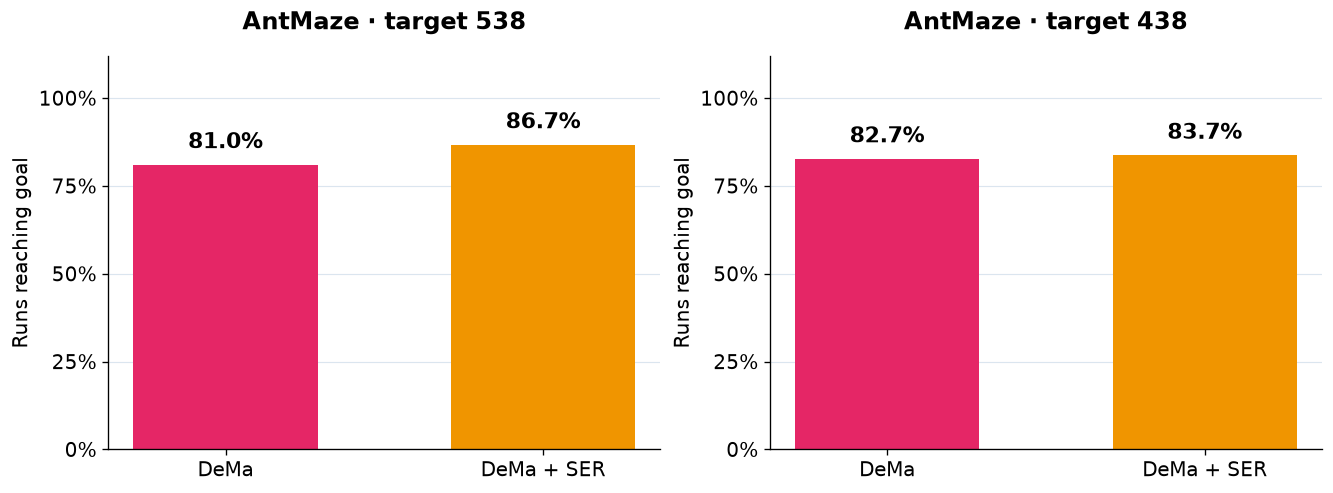

In [2]:
ser = {}
for target in [538, 438]:
    ser["DeMa", target] = evaluations("antmaze_dema", "DeMa", target)
    ser["DeMa + SER", target] = evaluations("ser_dema", "DeMa", target)
table([summary(label, ser[label, target], target, True) for target in [538, 438] for label in ["DeMa", "DeMa + SER"]])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, target in zip(axes, [538, 438]):
    labels = ["DeMa", "DeMa + SER"]
    rates = [summary(m, ser[m, target], target, True)["Goal arrival (%)"] for m in labels]
    bars(ax, labels, rates, [colors[m] for m in labels], f"AntMaze · target {target}", "Runs reaching goal", True)
save(fig, "ser_goals.png")

## SER: rewards across training runs

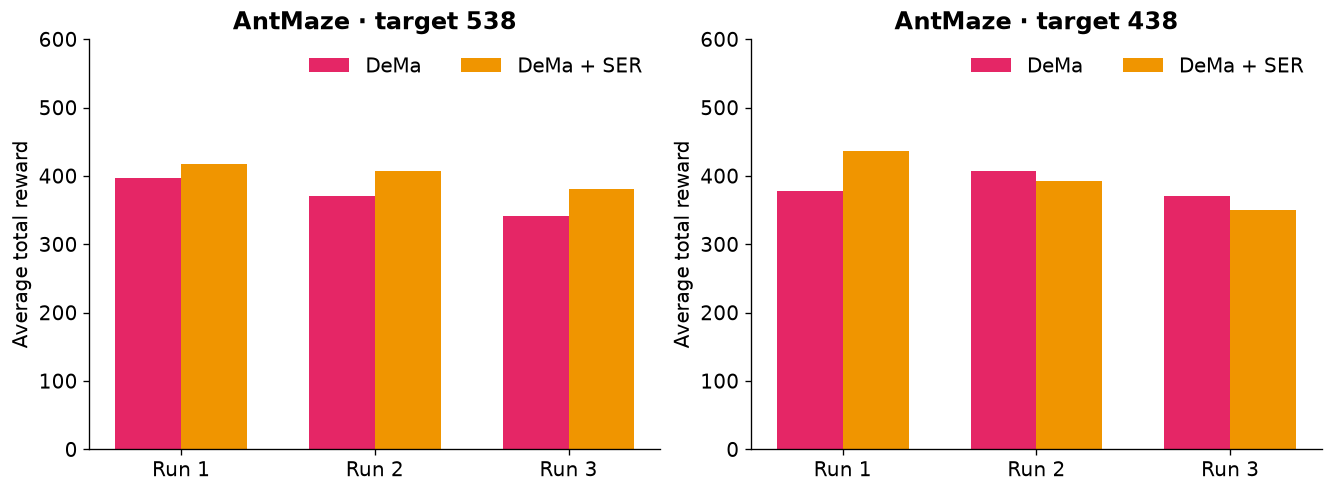

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
x = np.arange(3)
for ax, target in zip(axes, [538, 438]):
    for i, label in enumerate(["DeMa", "DeMa + SER"]):
        ax.bar(x + (i - 0.5) * 0.34, [r["return_mean"] for r in ser[label, target]],
               width=0.34, color=colors[label], label=label)
    ax.set_xticks(x, ["Run 1", "Run 2", "Run 3"])
    ax.set_title(f"AntMaze · target {target}", fontweight="bold")
    ax.set_ylabel("Average total reward")
    ax.set_ylim(0, 600)
    ax.legend(frameon=False, ncol=2, loc="upper right")
save(fig, "ser_reward.png")

## SER learning curves

SER training uses blended targets. Validation uses recorded actions in both panels. Curves average three runs from 10,000 updates.

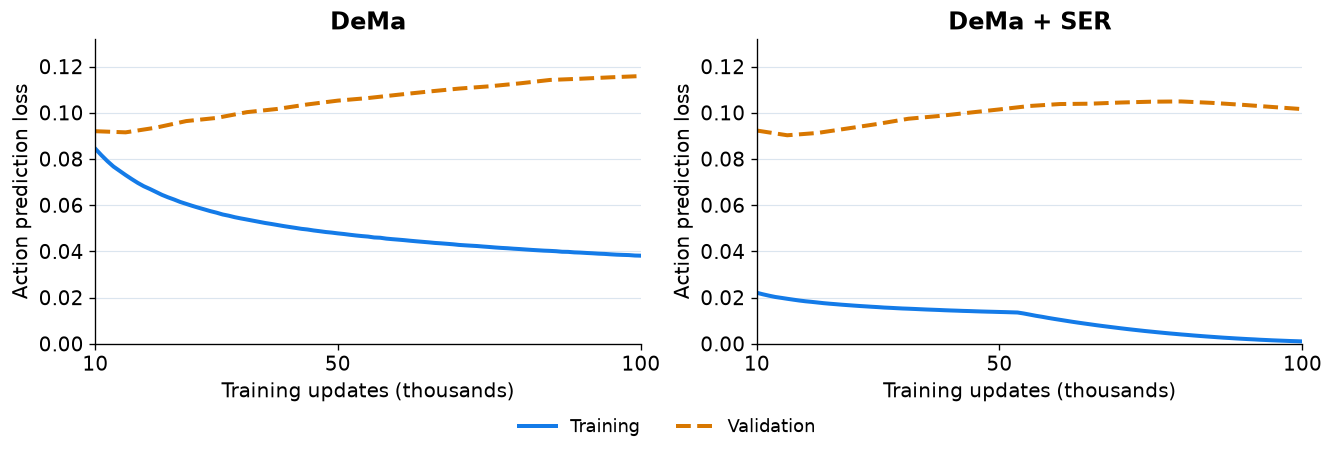

In [4]:
losses([("DeMa", "antmaze_dema", "DeMa"), ("DeMa + SER", "ser_dema", "DeMa")], "ser_loss.png")

## DeMa and Multi-Grained SSM

Both models use grouped inputs. Circles show three training-run averages.

,Task,Model,Target,Average reward,SD,Middle reward,Goal arrival (%)
0,HalfCheetah,DeMa,"12,000","11,637.5","1,103.1","13,012.2",nan
1,HalfCheetah,SSM,"12,000","9,735.6",378.8,"11,811.6",nan
2,AntMaze,DeMa,538,387.9,18.1,466.0,86.0
3,AntMaze,SSM,538,343.0,22.3,432.5,83.7
4,AntMaze,DeMa,438,396.0,11.6,461.5,86.7
5,AntMaze,SSM,438,330.4,31.5,414.5,78.7


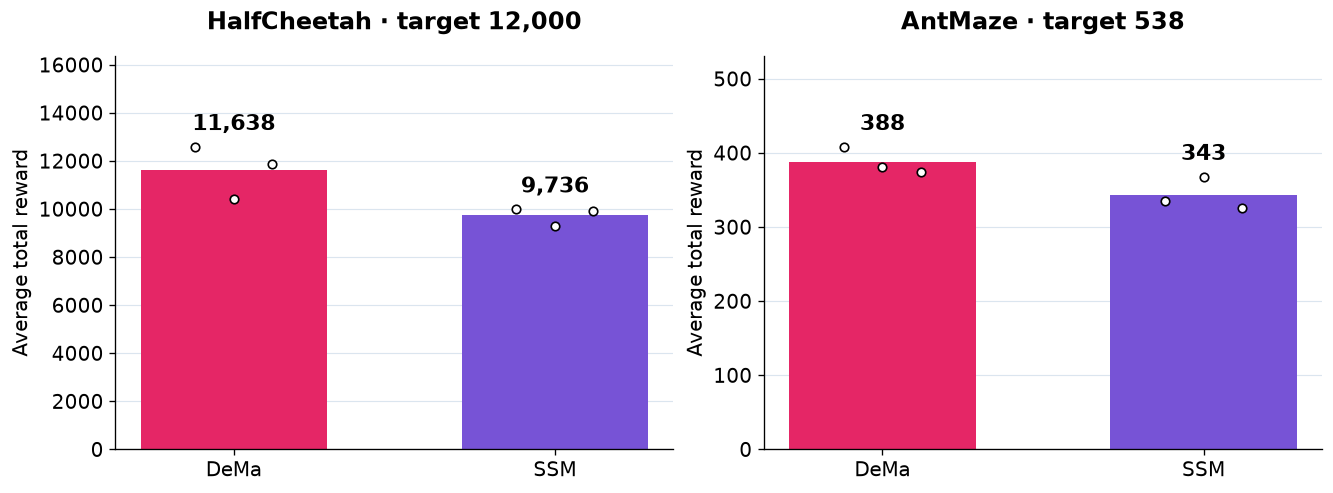

In [5]:
grouped = {}
for task, target, dema_prefix, ssm_prefix in [("HalfCheetah", 12000, "axis2_dema", "mgssm_grouped_halfcheetah"),
                                             ("AntMaze", 538, "dema_grouped_antmaze", "mgssm_grouped_antmaze"),
                                             ("AntMaze", 438, "dema_grouped_antmaze", "mgssm_grouped_antmaze")]:
    grouped[task, "DeMa", target] = evaluations(dema_prefix, "DeMa", target)
    grouped[task, "SSM", target] = evaluations(ssm_prefix, "Multi-Grained SSM", target)
table([dict(Task=task, **summary(model, rows, target, task == "AntMaze")) for (task, model, target), rows in grouped.items()])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, task, target in zip(axes, ["HalfCheetah", "AntMaze"], [12000, 538]):
    labels = ["DeMa", "SSM"]
    samples = [[r["return_mean"] for r in grouped[task, m, target]] for m in labels]
    bars(ax, labels, [np.mean(v) for v in samples], [colors[m] for m in labels],
         f"{task} · target {target:,}", "Average total reward", samples=samples)
save(fig, "ssm_reward.png")

## Grouped-model learning curves

Average of three training runs, shown from 10,000 updates.

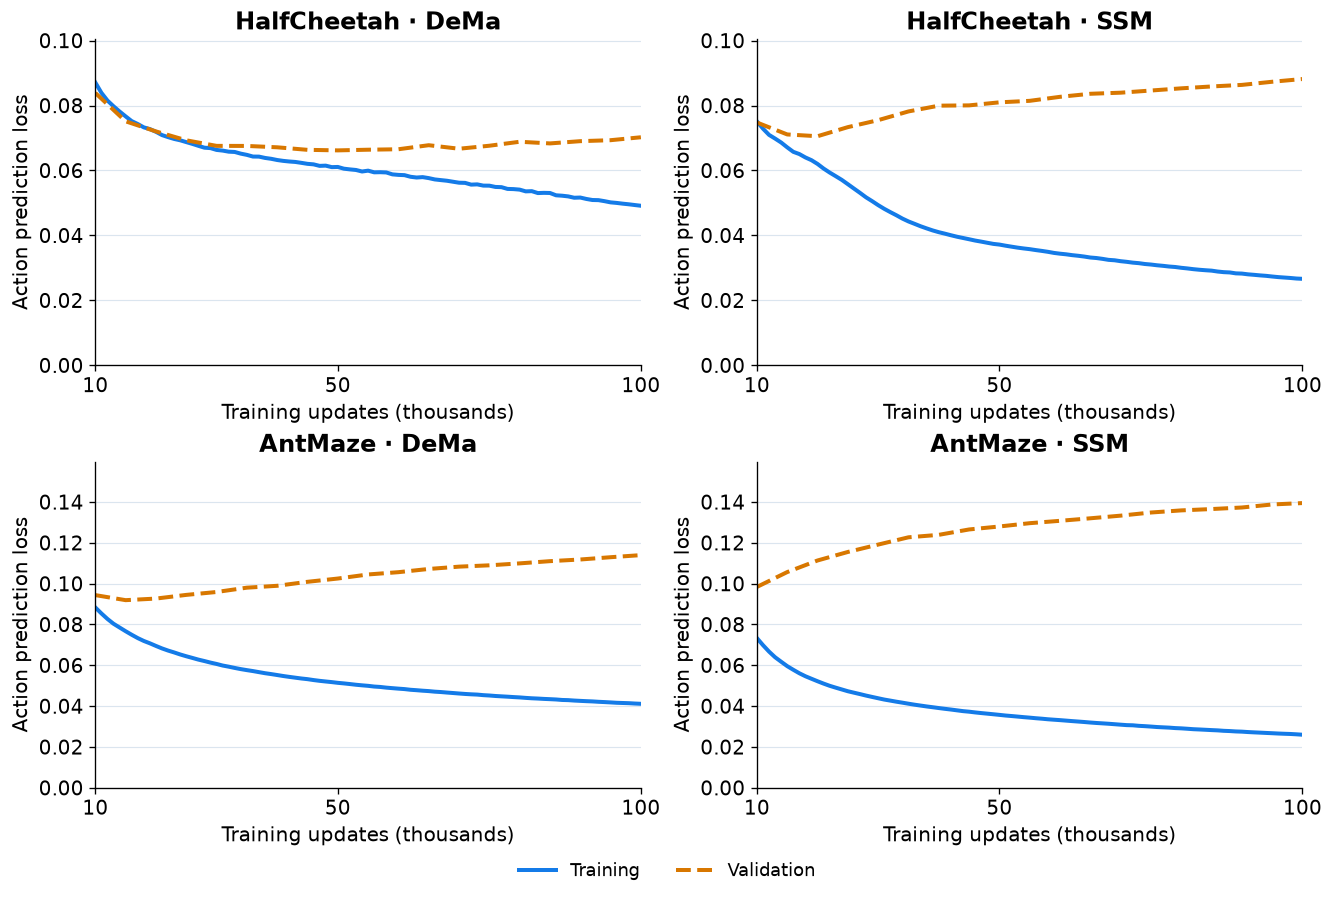

In [6]:
losses([("HalfCheetah · DeMa", "axis2_dema", "DeMa"),
        ("HalfCheetah · SSM", "mgssm_grouped_halfcheetah", "Multi-Grained SSM"),
        ("AntMaze · DeMa", "dema_grouped_antmaze", "DeMa"),
        ("AntMaze · SSM", "mgssm_grouped_antmaze", "Multi-Grained SSM")], "ssm_loss.png")

## Reward spread and model size

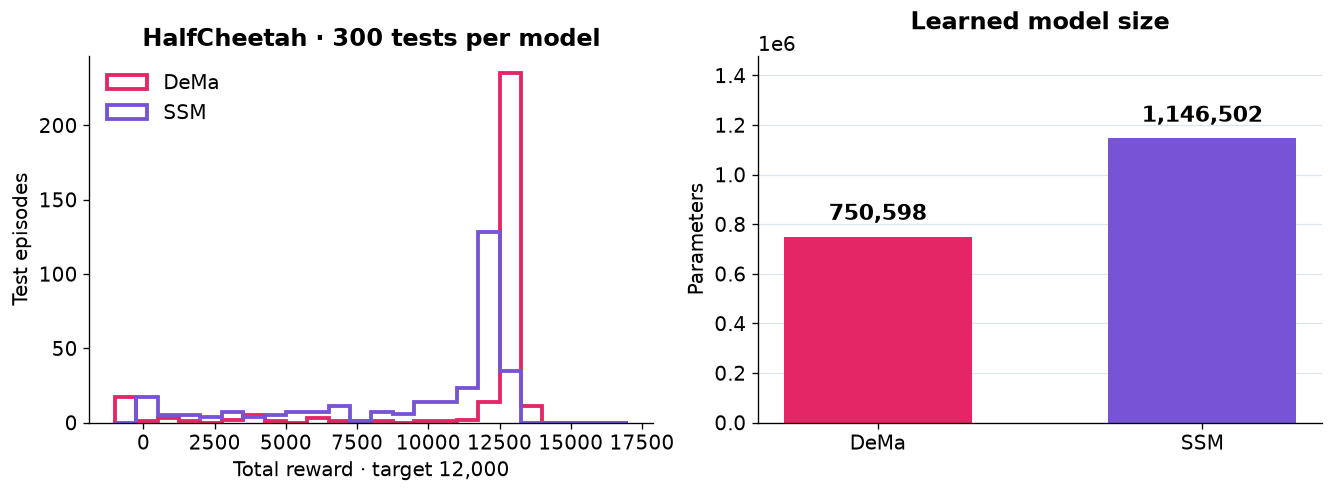

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for label in ["DeMa", "SSM"]:
    scores = np.concatenate([r["return_scores"] for r in grouped["HalfCheetah", label, 12000]])
    axes[0].hist(scores, bins=np.linspace(-1000, 17000, 25), histtype="step", linewidth=2.3, color=colors[label], label=label)
axes[0].set_title("HalfCheetah · 300 tests per model", fontweight="bold")
axes[0].set_xlabel("Total reward · target 12,000")
axes[0].set_ylabel("Test episodes")
axes[0].legend(frameon=False)
labels = ["DeMa", "SSM"]
bars(axes[1], labels, [grouped["HalfCheetah", m, 12000][0]["parameters"] for m in labels],
     [colors[m] for m in labels], "Learned model size", "Parameters")
save(fig, "ssm_size_spread.png")

## W&B histories

In [8]:
names = [f"{prefix}_seed{seed}" for prefix in ["ser_dema", "antmaze_dema", "axis2_dema", "mgssm_grouped_halfcheetah", "dema_grouped_antmaze", "mgssm_grouped_antmaze"] for seed in seeds]
logs = {}
if os.environ.get("WANDB_API_KEY"):
    import wandb
    api = wandb.Api(timeout=30)
    entity = os.environ.get("WANDB_ENTITY") or api.default_entity
    project = os.environ.get("WANDB_PROJECT", "dema-vs-dt")
    for run in api.runs(f"{entity}/{project}"):
        if run.name in names:
            logs[run.name] = list(run.scan_history(page_size=200))
    print(f"Loaded {len(logs)} run histories")